结构化输出是Agent的核心功能之一，它允许Agent以特定、可预测的格式返回数据，而不是传统的自然语言响应。通过结构化输出，开发者可以直接获得 Pydantic模型 、 JSON对象 或 数据类 等结构化数据，这些数据能够被应用程序直接使用，无需复杂的解析过程。

https://docs.langchain.com/oss/python/langchain/structured-output

## 1、模型 vs agent的结构化输出对比

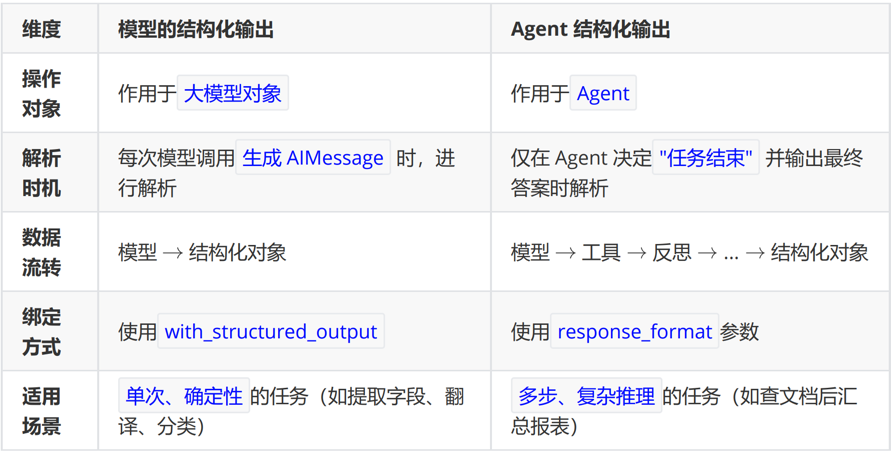

## 2、结构化输出的4种策略

LangChain的create_agent()函数自动处理结构化输出的全过程。用户只需要通过`response_format`参数设置期望的输出模式（schema）。

当模型生成结构化数据时，系统会自动捕获、验证并将结果存储在Agent状态的`structured_response`键中。

In [ ]:
def create_agent(
    ...
    response_format: Union[
        ToolStrategy[StructuredResponseT],
        ProviderStrategy[StructuredResponseT],
        type[StructuredResponseT],
        None,
    ]
)

create_agent函数中的response_format参数支持四种不同的策略设置方式：

### 2.1 ProviderStrategy
使用模型提供商的原生结构化输出功能实现结构化输出。

- 这里所说的“原生结构化输出”指的是大语言模型（LLM）提供商通过其API直接提供的、在模型响应阶段就强制保证 输出格式符合预定规范 的能力，这种能力能够在模型生成内容的源头确保结构化准确性。
- 适用于支持原生结构化输出的模型，比如OpenAI、Anthropic Claude或xAI Grok等。

In [ ]:
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.structured_output import ProviderStrategy

load_dotenv(override=True)

# ds不支持该方式
model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL"),
    extra_body={"thinking": {"type": "disabled"}}
)

class ContactInfo(BaseModel):
    """用户的联系方式"""
    name: str = Field(description="用户姓名")
    email: str = Field(description="用户邮箱")
    phone: str = Field(description="用户手机号")

agent = create_agent(
    model = model,
    response_format=ProviderStrategy(schema=ContactInfo)
)

response = agent.invoke({
    "messages": ["从这段话中抽取结构化信息：小明的邮箱地址为：shkstart@atguigu.com，手机号：12345678912"]
})

print(response)

### 2.2 ToolStrategy
对于不支持原生结构化输出的模型，LangChain采用“ToolStrategy”工具调用的方式实现结构化输出。

此策略兼容绝大多数 支持工具调用 的现代模型，其核心原理是动态创建一个" 虚拟工具 "，该工具的输入参数对应着期望的数据结构。

当模型需要生成最终答案时，系统会引导模型 "调用"这个虚拟工具 ，从而间接产生符合要求的结构化数据。

In [ ]:
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from pydantic import BaseModel, Field
from langchain_core.tools import tool
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from rich import print as rprint

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL"),
    extra_body={"thinking": {"type": "disabled"}}
)

class ContactInfo(BaseModel):
    """用户的联系方式"""
    name: str = Field(description="用户姓名")
    email: str = Field(description="用户邮箱")
    phone: str = Field(description="用户手机号")

@tool
def search_tool(query: str) -> str:
    """这是一个搜索引擎。当大模型发现给定的上下文里缺少必要的联系人信息，
    需要去互联网上查询时，才会调用这个工具。
    """
    return f"搜索结果: 未找到关于 '{query}' 的更多额外信息。"

agent = create_agent(
    model=model,
    name="agent01",
    tools=[search_tool],
    response_format=ToolStrategy(ContactInfo)
)

result = agent.invoke({
"messages": [{"role": "user", "content": "联系人信息: John Doe,john@atguigu.com, (010) 56253825"}]
})
rprint(result)
print(result["structured_response"])

### 2.3 type/AutoStrategy
当我们传入一个定义类型时，LangChain会自动包装为AutoStrategy，触发自动选择策略。如果模型支持原生结构化输出（如OpenAI、Anthropic Claude或xAI Grok），则优先使用ProviderStrategy；否则使用ToolStrategy。

In [ ]:
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.structured_output import AutoStrategy
from rich import print as rprint

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL"),
    extra_body={"thinking": {"type": "disabled"}}
)

class ContactInfo(BaseModel):
    """用户的联系方式"""
    name: str = Field(description="用户姓名")
    email: str = Field(description="用户邮箱")
    phone: str = Field(description="用户手机号")

agent = create_agent(
    model=model,
    name="agent01",
    response_format=AutoStrategy(ContactInfo)
)

result = agent.invoke({
"messages": [{"role": "user", "content": "联系人信息: John Doe,john@atguigu.com, (010) 56253825"}]
})
rprint(result)
print(result["structured_response"])

### 2.4 None
默认配置，表示不以结构化输出，以自然语言响应用户问题。

## 3、总结
在实际大模型Agent开发场景中，如果使用到了结构化输出，推荐使用 “ToolStrategy”策略 。